In [1]:
from google.colab import files
import pandas as pd

# Upload your downloaded IMDb CSV file
uploaded = files.upload()

# Read the uploaded file
filename = list(uploaded.keys())[0]

try:
    df = pd.read_csv(filename)
except UnicodeDecodeError:
    df = pd.read_csv(filename, encoding="latin-1")

print("File loaded:", filename)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Saving IMDB Dataset.csv to IMDB Dataset.csv
File loaded: IMDB Dataset.csv
Dataset shape: (50000, 2)

Column names:
['review', 'sentiment']

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


# Explore and clean the dataset

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64

Duplicate rows: 418
Duplicate reviews: 418

Review length statistics:
count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review, dtype: float64

Cleaned dataset shape: (49582, 2)

Sentiment distribution after cleaning:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64

Cleaned review examples:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. The filming tec...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


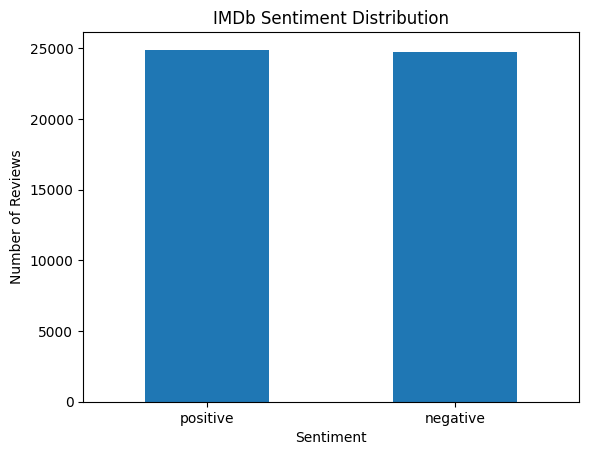

In [2]:
import pandas as pd
import re
import html
import matplotlib.pyplot as plt

# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check sentiment distribution
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nSentiment percentages:")
print((df["sentiment"].value_counts(normalize=True) * 100).round(2))

# 3. Check duplicate rows and reviews
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate reviews:", df["review"].duplicated().sum())

# 4. Check review lengths
print("\nReview length statistics:")
print(df["review"].str.len().describe())

# 5. Remove missing values and duplicate rows
df = df.dropna(subset=["review", "sentiment"]).copy()
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df = df.drop_duplicates(subset=["review"]).copy()

# 6. Clean HTML tags and HTML entities in reviews
def clean_review(text):
    text = html.unescape(str(text))
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review"] = df["review"].apply(clean_review)

# 7. Keep only the expected sentiment labels
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

# 8. Display the cleaned dataset
print("\nCleaned dataset shape:", df.shape)
print("\nSentiment distribution after cleaning:")
print(df["sentiment"].value_counts())

print("\nCleaned review examples:")
display(df[["review", "sentiment"]].head())

# 9. Plot sentiment distribution
df["sentiment"].value_counts().reindex(
    ["positive", "negative"]
).plot(kind="bar", rot=0)

plt.title("IMDb Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# Split the data and convert reviews into TF-IDF features

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

import numpy as np

# 1. Separate input text and target labels
X = df["review"]
y = df["sentiment"]

# 2. Convert labels to numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Label mapping:")
for label, number in zip(label_encoder.classes_,
                         label_encoder.transform(label_encoder.classes_)):
    print(f"{label} = {number}")

# 3. Split into training and testing sets (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Convert reviews into TF-IDF features
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    dtype=np.float32
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# 5. Display feature information
print("\nTF-IDF preprocessing completed!")
print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf_vectorizer.get_feature_names_out()))

print("\nSample TF-IDF features:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

Label mapping:
negative = 0
positive = 1

Training samples: 39665
Testing samples: 9917

TF-IDF preprocessing completed!
Training feature matrix: (39665, 5000)
Testing feature matrix: (9917, 5000)
Number of TF-IDF features: 5000

Sample TF-IDF features:
['00' '000' '10' '100' '11' '12' '13' '13th' '14' '15' '16' '17' '18'
 '1930' '1930s' '1939' '1940' '1950' '1950s' '1960']


# Prepare the CPU vs GPU experiment

In [6]:
import torch
import numpy as np
import random

# Check available hardware
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Check Runtime settings.")

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("\nTraining samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("TF-IDF features:", X_train_tfidf.shape[1])
print("Number of classes:", len(np.unique(y_train)))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4

Training samples: 39665
Testing samples: 9917
TF-IDF features: 5000
Number of classes: 2


# Check the GPU again

In [7]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU is still unavailable.")
    !nvidia-smi

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4


# Train the same neural network on CPU and GPU

In [8]:
import time
import copy
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report

# 1. Set experiment settings
INPUT_SIZE = X_train_tfidf.shape[1]  # 5000
HIDDEN_SIZE = 128
OUTPUT_SIZE = 2
EPOCHS = 5
BATCH_SIZE = 256
LEARNING_RATE = 0.001

device_gpu = torch.device("cuda")
device_cpu = torch.device("cpu")

# Convert labels to NumPy arrays
y_train_np = np.asarray(y_train, dtype=np.int64)
y_test_np = np.asarray(y_test, dtype=np.int64)


# 2. Define the neural network
class SentimentNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(INPUT_SIZE, HIDDEN_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_SIZE, OUTPUT_SIZE)
        )

    def forward(self, x):
        return self.network(x)


# 3. Create one initial model so both experiments start
# with exactly the same weights
torch.manual_seed(42)
initial_model = SentimentNN()
initial_weights = copy.deepcopy(initial_model.state_dict())

# Use the same shuffled batch order for both devices
rng = np.random.default_rng(42)
batch_orders = [
    rng.permutation(len(y_train_np))
    for _ in range(EPOCHS)
]


# 4. Function to train and evaluate on a chosen device
def run_experiment(device, experiment_name):
    model = SentimentNN().to(device)
    model.load_state_dict(initial_weights)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    model.train()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    # Training loop
    for epoch in range(EPOCHS):
        order = batch_orders[epoch]

        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]

            # Convert only the current sparse batch to dense
            batch_x = X_train_tfidf[indices].toarray()
            batch_y = y_train_np[indices]

            batch_x = torch.from_numpy(
                batch_x.astype(np.float32, copy=False)
            ).to(device)

            batch_y = torch.from_numpy(batch_y).to(device)

            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    # Evaluate test data in batches
    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, X_test_tfidf.shape[0], BATCH_SIZE):
            end = min(start + BATCH_SIZE, X_test_tfidf.shape[0])

            batch_x = X_test_tfidf[start:end].toarray()
            batch_x = torch.from_numpy(
                batch_x.astype(np.float32, copy=False)
            ).to(device)

            outputs = model(batch_x)
            predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )

    accuracy = accuracy_score(y_test_np, predictions)

    print(f"\n===== {experiment_name} RESULTS =====")
    print(f"Device: {device}")
    print(f"Training time: {training_time:.4f} seconds")
    print(f"Test accuracy: {accuracy * 100:.2f}%")
    print("\nClassification report:")
    print(classification_report(
        y_test_np,
        predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

    return {
        "device": experiment_name,
        "training_time": training_time,
        "accuracy": accuracy * 100
    }


# 5. Run both experiments
cpu_results = run_experiment(device_cpu, "CPU")
gpu_results = run_experiment(device_gpu, "GPU")


# 6. Compare results
import pandas as pd

comparison = pd.DataFrame([cpu_results, gpu_results])

print("\n===== CPU vs GPU COMPARISON =====")
display(comparison.round(4))

speedup = cpu_results["training_time"] / gpu_results["training_time"]

print(f"\nGPU speedup relative to CPU: {speedup:.2f}x")


===== CPU RESULTS =====
Device: cpu
Training time: 8.3239 seconds
Test accuracy: 88.03%

Classification report:
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88      4940
    Positive       0.88      0.88      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917


===== GPU RESULTS =====
Device: cuda
Training time: 2.7196 seconds
Test accuracy: 88.03%

Classification report:
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88      4940
    Positive       0.88      0.88      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917


===== CPU vs GPU COMPARISON =====


,device,training_time,accuracy
0,CPU,8.3239,88.0307
1,GPU,2.7196,88.0307



GPU speedup relative to CPU: 3.06x


# Comparison Agent: CPU vs GPU — Pictorial Report

**Your responsibility:** compare the same neural-network model on CPU and GPU. This notebook focuses on backend execution, visual explanation, measured performance, and conclusions. It does not build a frontend or replace the ML model.

## 1. Backend execution: what happens when the notebook runs

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_box(ax, xy, w, h, title, subtitle, color):
    box = FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.03,rounding_size=0.04", linewidth=1.5, edgecolor=color, facecolor=color, alpha=0.14)
    ax.add_patch(box)
    ax.text(xy[0]+w/2, xy[1]+h*0.64, title, ha='center', va='center', fontsize=10, fontweight='bold', color=color)
    ax.text(xy[0]+w/2, xy[1]+h*0.30, subtitle, ha='center', va='center', fontsize=8, wrap=True, color='black')

def arrow(ax, start, end):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>', mutation_scale=14, linewidth=1.4, color='#555555'))

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.set_xlim(0, 13); ax.set_ylim(0, 5); ax.axis('off')
draw_box(ax,(0.2,2.0),1.8,1.25,'IMDb reviews','Raw text + labels','#3568A8')
draw_box(ax,(2.5,2.0),1.8,1.25,'TF-IDF','Text → 5,000 features','#8B5FBF')
draw_box(ax,(4.8,2.0),1.8,1.25,'Same model','Same weights, batches, epochs','#B06B28')
draw_box(ax,(7.3,3.25),2.0,1.1,'CPU run','Compute on CPU','#277A57')
draw_box(ax,(7.3,0.75),2.0,1.1,'GPU run','Compute on CUDA GPU','#277A57')
draw_box(ax,(10.1,2.0),2.4,1.25,'Compare results','Time • accuracy • speedup','#3568A8')
arrow(ax,(2.0,2.62),(2.5,2.62)); arrow(ax,(4.3,2.62),(4.8,2.62)); arrow(ax,(6.6,2.75),(7.3,3.75)); arrow(ax,(6.6,2.45),(7.3,1.30)); arrow(ax,(9.3,3.75),(10.1,2.85)); arrow(ax,(9.3,1.30),(10.1,2.35))
ax.set_title('Backend flow: one dataset and model, two hardware runs', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout(); plt.show()

## 2. What is different inside the CPU and GPU?

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
fig.suptitle('CPU vs GPU: conceptual processing layout', fontsize=15, fontweight='bold')
# CPU: few general-purpose cores
axes[0].set_title('CPU — fewer, powerful general-purpose cores')
axes[0].set_xlim(0, 4); axes[0].set_ylim(0, 4); axes[0].axis('off')
for i in range(2):
    for j in range(2):
        p=FancyBboxPatch((0.55+j*1.55,1.55+i*1.05),1.15,0.7,boxstyle='round,pad=0.04',facecolor='#D8E8F8',edgecolor='#3568A8',linewidth=1.5)
        axes[0].add_patch(p); axes[0].text(1.125+j*1.55,1.9+i*1.05,f'Core {i*2+j+1}',ha='center',va='center',fontsize=10)
axes[0].text(2,0.8,'Good at varied, sequential tasks\nand general system work',ha='center',va='center',fontsize=10)
# GPU: many small parallel units
axes[1].set_title('GPU — many smaller parallel processing units')
axes[1].set_xlim(0, 4); axes[1].set_ylim(0, 4); axes[1].axis('off')
for i in range(5):
    for j in range(8):
        p=FancyBboxPatch((0.3+j*0.43,1.45+i*0.38),0.31,0.25,boxstyle='round,pad=0.01',facecolor='#D9F0E4',edgecolor='#277A57',linewidth=0.7)
        axes[1].add_patch(p)
axes[1].text(2,0.8,'Can perform many similar arithmetic\noperations at the same time',ha='center',va='center',fontsize=10)
plt.tight_layout(); plt.show()
print('Why GPU can be faster: neural-network training performs large batches of matrix operations that can run in parallel.')
print('Why GPU is not always faster: moving data to/from GPU has overhead, and small workloads may not use its parallel capacity efficiently.')

## 3. Actual CPU vs GPU results (measured by your experiment)

In [ ]:
import pandas as pd
required_keys = {'device', 'training_time', 'accuracy'}
if not all(required_keys.issubset(r.keys()) for r in [cpu_results, gpu_results]):
    raise ValueError('CPU/GPU result dictionaries are missing expected keys. Run the CPU/GPU experiment cell first.')
results = pd.DataFrame([
    {'Device': cpu_results['device'], 'Training time (seconds)': float(cpu_results['training_time']), 'Test accuracy (%)': float(cpu_results['accuracy'])},
    {'Device': gpu_results['device'], 'Training time (seconds)': float(gpu_results['training_time']), 'Test accuracy (%)': float(gpu_results['accuracy'])}
])
results['Training throughput (samples/second)'] = len(X_train) / results['Training time (seconds)']
display(results.round(3))
cpu_time=float(cpu_results['training_time']); gpu_time=float(gpu_results['training_time'])
if gpu_time > 0:
    speedup=cpu_time/gpu_time
    print(f'GPU speedup (CPU time ÷ GPU time): {speedup:.2f}×')
    if speedup > 1: print(f'Interpretation: GPU training was {speedup:.2f} times as fast in this run.')
    elif speedup < 1: print(f'Interpretation: GPU was slower in this run; CPU was {1/speedup:.2f} times as fast.')
    else: print('Interpretation: CPU and GPU training times were equal in this run.')
print(f'Absolute test-accuracy difference: {abs(float(cpu_results["accuracy"])-float(gpu_results["accuracy"])):.2f} percentage points')

In [ ]:
# Pictorial charts use the actual results above (not illustrative numbers).
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = [
    ('Training time (seconds)', 'Training time (lower is better)'),
    ('Test accuracy (%)', 'Test accuracy (higher is better)'),
    ('Training throughput (samples/second)', 'Training throughput (higher is better)')
]
for ax, (col, title) in zip(axes, metrics):
    bars=ax.bar(results['Device'], results[col])
    ax.set_title(title); ax.set_ylabel(col); ax.tick_params(axis='x', rotation=12)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
    ax.margins(y=0.18)
plt.suptitle('Measured CPU vs GPU comparison', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

## 4. How to explain your result in the presentation

In [ ]:
print('COMPARISON AGENT SUMMARY')
print('- Dataset and TF-IDF features are the same for both runs.')
print('- Both runs use the same neural-network structure, initial weights, batch size, epochs and batch order.')
print(f'- CPU training time: {cpu_time:.3f} seconds; test accuracy: {float(cpu_results["accuracy"]):.2f}%.')
print(f'- GPU training time: {gpu_time:.3f} seconds; test accuracy: {float(gpu_results["accuracy"]):.2f}%.')
if gpu_time > 0:
    if cpu_time > gpu_time: print(f'- GPU was faster by {cpu_time-gpu_time:.3f} seconds ({cpu_time/gpu_time:.2f}× speedup).')
    elif cpu_time < gpu_time: print(f'- CPU was faster by {gpu_time-cpu_time:.3f} seconds in this run.')
    else: print('- Both devices had the same measured training time.')
print('- Accuracy difference alone does not show hardware speed; use timing and accuracy together.')
print('- Repeat the experiment if possible. GPU startup/warm-up, Colab hardware, and data-transfer overhead can affect timing.')

## Comparison-agent checklist

- Report **measured values from your own Colab run**, not sample numbers.
- Compare the same model, same data split, same initial weights, epochs, and batch order.
- Present the backend flow diagram, CPU/GPU processing diagram, and measured charts.
- Explain both speed and accuracy; do not claim the GPU is always faster.
- This notebook intentionally focuses on comparison and backend explanation, not frontend development.